In [12]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
from IPython.display import Latex
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')

from scipy.stats import uniform_direction
from reverse_orbit import reverse_orbit
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
sys.path.append('/suphys/aani0116/Work/minicluster_tidal/stellar')
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
import corner
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [13]:
simulation_time=10
#s_pos=[8.0,0.0,0.0]
#final_pos=generate_xv_at(s_pos,1)[0]
#mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
#mc_start=mc_center.copy()
#mc_end=final_pos.copy()
#mcp_xv,mcp_mass=np.empty((0, 6)),np.array([])   

final_pos=np.array([8.0,0.0,0.0,1.0,1.0,220.0])
mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
mc_start=mc_center.copy()
mc_end=final_pos.copy()
mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 

In [14]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius:',mc.mass,mc.radius,)



mass and radius: 1.204020085327871e-13 3.971099897155001e-12


In [15]:
orb=agama.orbit(ic=mc_center, potential=pot_mw, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)


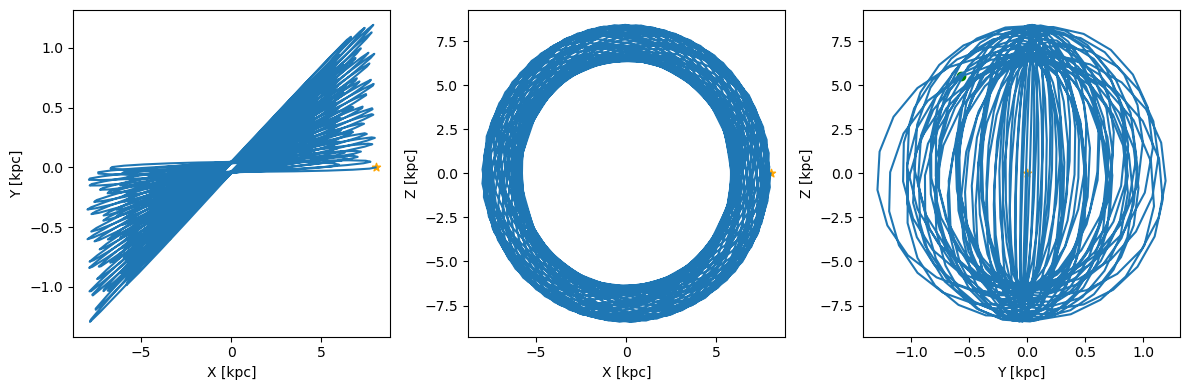

In [16]:
t=np.linspace(0,simulation_time,1000)
o=orb(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [17]:
def stellar_energy(N,M,R,v,its_sum):
    b=np.random.uniform(100*R, 1e-4,N) #is this a good choice?
    E=((4*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2)*3)
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [18]:
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)


In [19]:
tupd = 1e-2
time_i = 0


mc_mass=mc.mass
mc_rvir=mc.radius
print('simulation time',simulation_time)


simulation time 10


In [20]:
#random stuff for plotting
mc_array=[mc_center]
mc_time=[]
pnum_array=[]
mass_array,radius_array=[],[]
Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
color=[0]

In [21]:
color_index=0
while time_i < simulation_time:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=100, accuracy=1e-16,verbose=False)

    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=0.0001)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    

    Ei=binding_energy(mc_mass,mc_rvir)
    delEbyE=abs(delE/Ei)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=total_energy(Ei)+(1-get_fej(delEbyE))*delE+get_fub(delEbyE)*total_energy(Ei)
    
    Ef_array.append(Ef)
    Ei_array.append(total_energy(Ei))
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*total_energy(Ei))
    
    mc_mass=mc_mass-mass_loss
    mc_rvir=(kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef if N_encounter_with_star > 1 else mc_rvir     #mass and radius update
    

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)
    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)
    if mc_rvir==0:
        print('dead')
        break
    
    
    

    
    
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
        #if mcp_xv.size>0: mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0) 
    if mcp_xv.size>0:mcp_xv_temp+=mc_orbit_center[-1]
    else: mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
 
    if pnum>0:
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1 

    mc_center = mc_orbit_center[-1]

    time_i += tupd
    print(time_i)
color=np.array(color[1:])


0.01
0.02
0.03
0.04
0.05
0.060000000000000005
0.07
0.08
0.09
0.09999999999999999
0.10999999999999999
0.11999999999999998
0.12999999999999998
0.13999999999999999
0.15
0.16
0.17
0.18000000000000002
0.19000000000000003
0.20000000000000004
0.21000000000000005
0.22000000000000006
0.23000000000000007
0.24000000000000007
0.25000000000000006
0.26000000000000006
0.2700000000000001
0.2800000000000001
0.2900000000000001
0.3000000000000001
0.3100000000000001
0.3200000000000001
0.3300000000000001
0.34000000000000014
0.35000000000000014
0.36000000000000015
0.37000000000000016
0.38000000000000017
0.3900000000000002
0.4000000000000002
0.4100000000000002
0.4200000000000002
0.4300000000000002
0.4400000000000002
0.45000000000000023
0.46000000000000024
0.47000000000000025
0.48000000000000026
0.49000000000000027
0.5000000000000002
0.5100000000000002
0.5200000000000002
0.5300000000000002
0.5400000000000003
0.5500000000000003
0.5600000000000003
0.5700000000000003
0.5800000000000003
0.5900000000000003
0.60000

1.1200000000000008
1.1300000000000008
1.1400000000000008
1.1500000000000008
1.1600000000000008
1.1700000000000008
1.1800000000000008
1.1900000000000008
1.2000000000000008
1.2100000000000009
1.2200000000000009
1.2300000000000009
1.2400000000000009
1.2500000000000009
1.260000000000001
1.270000000000001
1.280000000000001
1.290000000000001
1.300000000000001
1.310000000000001
1.320000000000001
1.330000000000001
1.340000000000001
1.350000000000001
1.360000000000001
1.370000000000001
1.380000000000001
1.390000000000001
1.400000000000001
1.410000000000001
1.420000000000001
1.430000000000001
1.440000000000001
1.450000000000001
1.460000000000001
1.470000000000001
1.480000000000001
1.490000000000001
1.500000000000001
1.5100000000000011
1.5200000000000011
1.5300000000000011
1.5400000000000011
1.5500000000000012
1.5600000000000012
1.5700000000000012
1.5800000000000012
1.5900000000000012
1.6000000000000012
1.6100000000000012
1.6200000000000012
1.6300000000000012
1.6400000000000012
1.6500000000000012

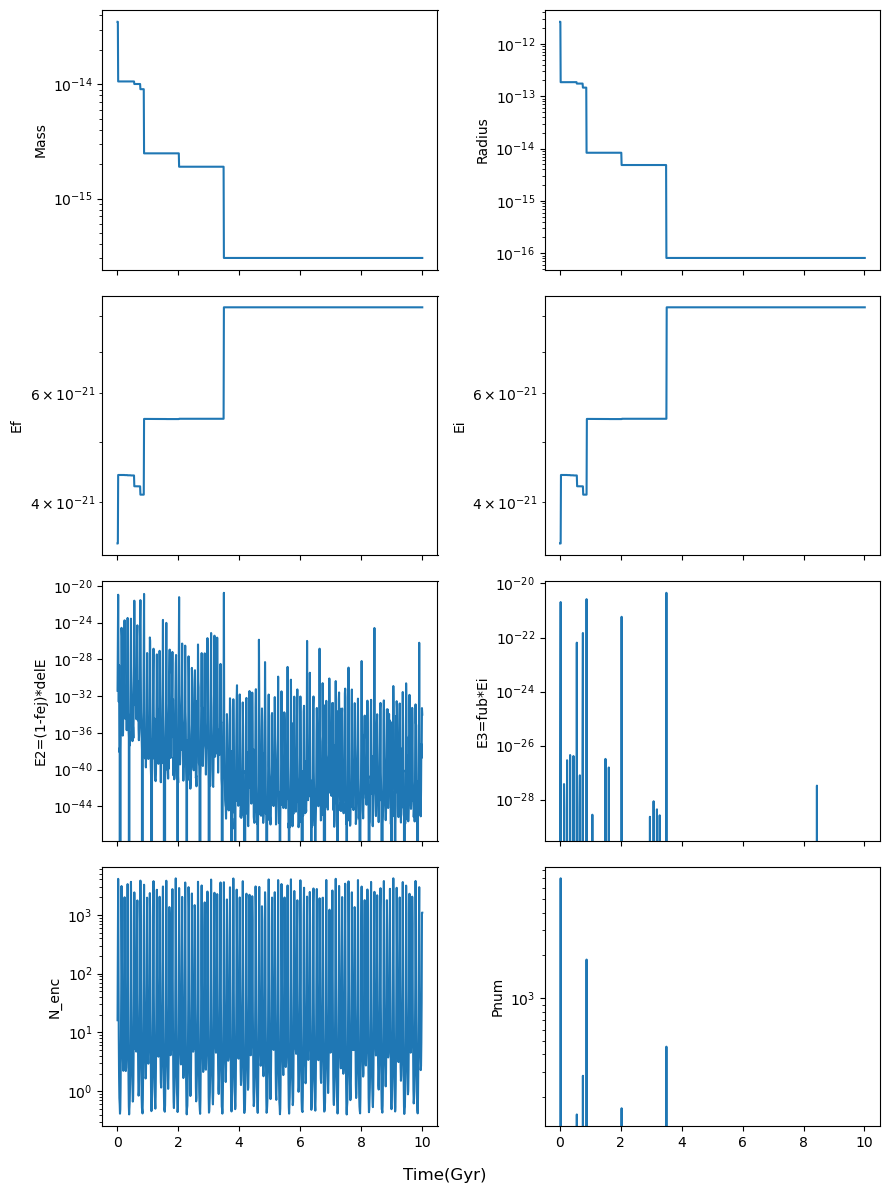

In [40]:
fig,ax=plt.subplots(4,2,figsize=(9,12),sharex=1)
ax[0,0].plot(mc_time,np.array(mass_array))
ax[0,0].set_ylabel('Mass')
ax[0,0].set_yscale('log')

ax[0,1].plot(mc_time,np.array(radius_array))
ax[0,1].set_ylabel('Radius')
ax[0,1].set_yscale('log')

ax[1,0].plot(mc_time,-np.array(Ef_array))
ax[1,0].set_ylabel('Ef')
ax[1,0].set_yscale('log')

ax[1,1].plot(mc_time,-np.array(Ei_array))
ax[1,1].set_ylabel('Ei')
ax[1,1].set_yscale('log')

ax[2,0].plot(mc_time,np.array(E2_array))
ax[2,0].set_ylabel('E2=(1-fej)*delE')
ax[2,0].set_yscale('log')

ax[2,1].plot(mc_time,-np.array(E3_array))
ax[2,1].set_ylabel('E3=fub*Ei')
ax[2,1].set_yscale('log')

ax[3,0].plot(mc_time,N_encounter_with_star_array)
ax[3,0].set_ylabel('N_enc')
ax[3,0].set_yscale('log')

ax[3,1].plot(mc_time,pnum_array)
ax[3,1].set_ylabel('Pnum')
ax[3,1].set_yscale('log')

fig.supxlabel('Time(Gyr)')

plt.tight_layout()

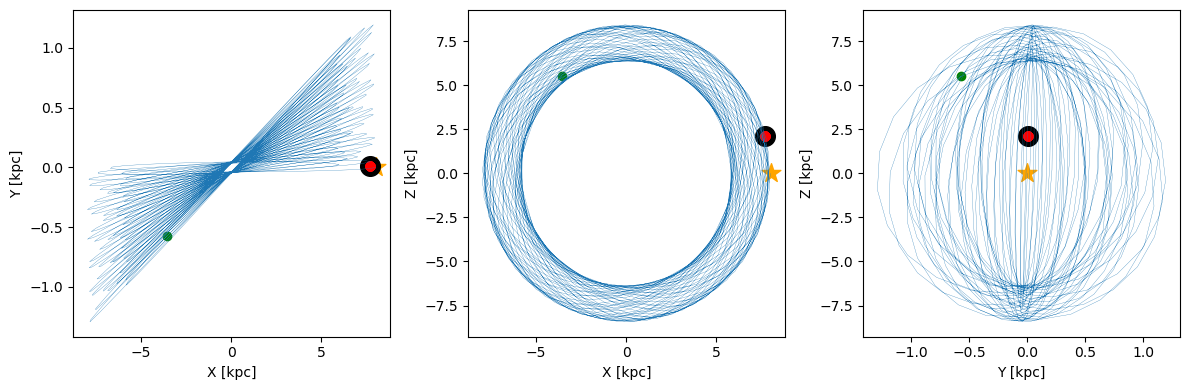

In [41]:
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1],lw=0.2)
ax[0].scatter(mc_end[0],mc_end[1],c='orange',marker='*',s=200)
ax[0].scatter(mc_start[0],mc_start[1],c='green')
ax[0].scatter(mc_center[0],mc_center[1],c='k',s=200)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],c='r')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2],lw=0.2)
ax[1].scatter(mc_end[0],mc_end[2],c='orange',marker='*',s=200)
ax[1].scatter(mc_center[0],mc_center[2],c='k',s=200)
ax[1].scatter(mc_start[0],mc_start[2],c='green')
ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],c='r')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2],lw=0.2)
ax[2].scatter(mc_end[1],mc_end[2],c='orange',marker='*',s=200)
ax[2].scatter(mc_center[1],mc_center[2],c='k',s=200)
ax[2].scatter(mc_start[1],mc_start[2],c='green')
ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],c='r')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()
plt.show()


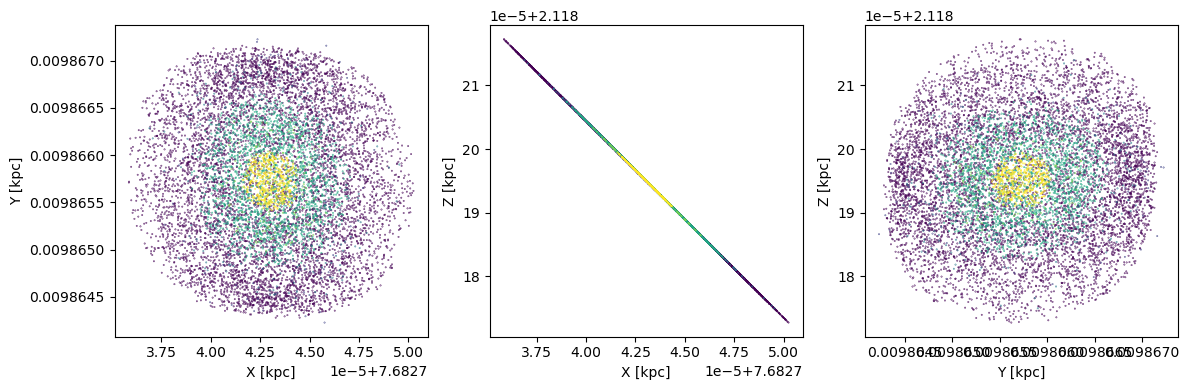

In [43]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

#PCA

In [17]:
mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
pca=PCA(n_components=3)
mcp_xr=pca.fit_transform(mcp_xc)

[1.14196349e-05 9.32150774e-07 1.30401385e-08]


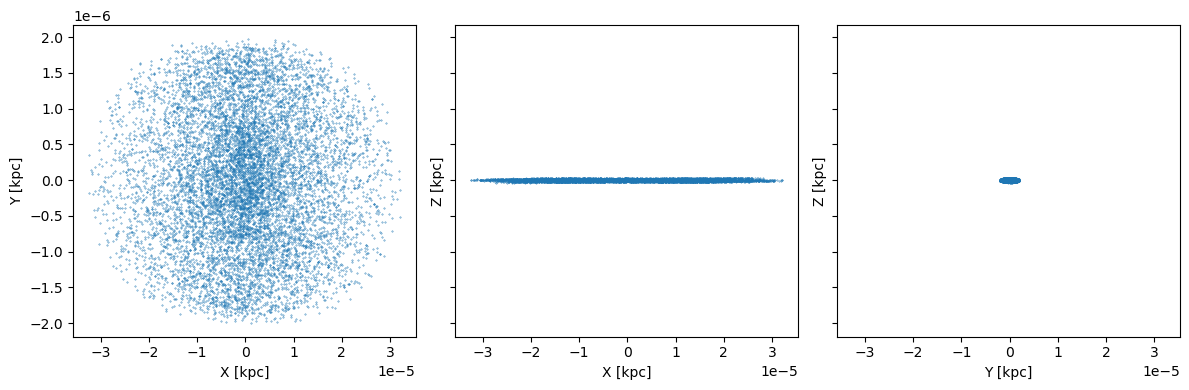

In [18]:
print(pca.explained_variance_**0.5)
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)

ax[0].scatter(mcp_xr[:,0],mcp_xr[:,1],s=0.1)
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xr[:,0],mcp_xr[:,2],s=0.1)
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xr[:,1],mcp_xr[:,2],s=0.1)
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

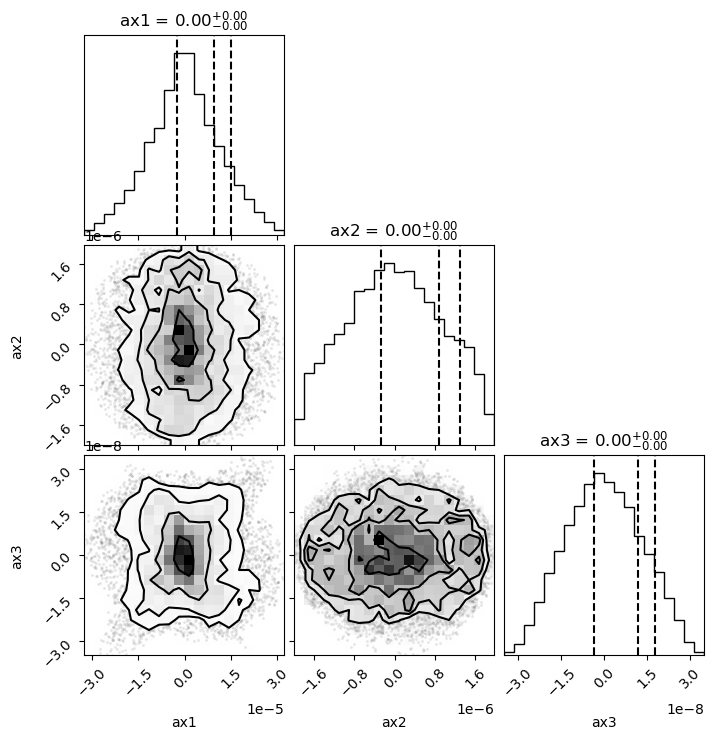

In [19]:
figure=corner.corner(mcp_xr,labels=['ax1','ax2','ax3'],axes_scale='linear',quantiles=[0.4,0.8,0.9],show_titles=True)

In [ ]:
pca.explained_variance_**0.5

In [ ]:
pca.explained_variance_ratio_

In [ ]:
pca.components_

In [ ]:
np.savez(f"data/mc{i}.npy",
         mcp_xv=mcp_xv,
         mcp_mass=mcp_mass,
         mc_mass=mc.mass,
         mc_radius=mc.radius,
         mc_center=mc_center,
         color=color,
         mc_start=mc_center_start,
         mc_end=final_pos
         )
